# ĐỒ ÁN: DỰ ĐOÁN GIÁ RAM BẰNG XGBOOST REGRESSOR

**Sinh viên:** Khôi  
**Bài toán:** Học máy có giám sát – Hồi quy (Regression)  
**Dữ liệu chính:** `ram_pricing_intelligence_2026.csv` (2.899 bản ghi, 17 thuộc tính).

## Mục tiêu
- Khám phá và làm sạch dữ liệu RAM.
- Phân tích các yếu tố liên quan đến giá bán.
- Xây dựng mô hình `XGBRegressor` để dự đoán `price`.
- Đánh giá mô hình bằng MAE, RMSE và R²; trực quan hóa kết quả và mức độ quan trọng của đặc trưng.

> **Lưu ý về dữ liệu:** Ba tệp CSV còn lại được giữ trong thư mục `data/` để tham khảo/EDA bổ sung. Chúng có cấu trúc và phạm vi quan sát khác nhau, vì vậy không gộp trực tiếp vào tập huấn luyện chính để tránh sai lệch đơn vị và trùng lặp.

## 1. Khai báo thư viện

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)
RANDOM_STATE = 42

## 2. Đọc dữ liệu và kiểm tra tổng quan

In [2]:
DATA_DIR = 'data'
main_file = os.path.join(DATA_DIR, 'ram_pricing_intelligence_2026.csv')
df = pd.read_csv(main_file)

print(f'Kích thước dữ liệu: {df.shape[0]} dòng × {df.shape[1]} cột')
display(df.head())

Kích thước dữ liệu: 2899 dòng × 17 cột


,ram_generation,brand,seller_id,condition,title,capacity_gb,bus_speed_mhz,unit_type,price,wasPrice,available,sold,itemLocation,lastUpdated,mpn,type,is_bulk_server
0,DDR4,SK hynix,Seller_0001,Used,SK Hynix 64GB 4DRx4 PC4-2400T DDR4 ECC Server ...,64.0,2400.0,Single,229.00,NaN,6.0,2.0,"Lakeville, Minnesota, United States",2026-04-24 21:22:14,HMAA8GL7MMR4NUH,DDR4 SDRAM,1
1,DDR4,A-Tech,Seller_0002,New,A-Tech 32GB 2x 16GB PC4-21300 Laptop SODIMM 26...,32.0,2666.0,Dual Kit,231.98,NaN,10.0,1728.0,"Columbus, Ohio, United States",2026-04-20 10:40:28,AT16G2D4S2666ND8N12V,DDR4 SDRAM,0
2,DDR4,Crucial,Seller_0003,Used,16GB Crucial Micron DDR4-2133 PC4-17000 RDIMM ...,16.0,2133.0,Single,57.99,NaN,8.0,28.0,"Las Vegas, Nevada, United States",2026-04-24 20:40:30,"CT16G4RFD4213, CT16G4RFD4213.36FA2, CT16G4RFD4...",DDR4 SDRAM,1
3,DDR4,SK hynix,Seller_0004,Used,SK HYNIX 32GB HMA84GR7MFR4N-UH DDR4-2400 2Rx4 ...,32.0,2400.0,Single,189.99,NaN,10.0,3.0,"Wauconda, Illinois, United States",2026-04-18 08:03:11,HMA84GR7MFR4NUH,ECC RAM,0
4,DDR4,RAM,Seller_0005,Used,Mixed Brand 8GB DDR4 Desktop RAM PC4 UDIMM - C...,8.0,NaN,Single,23.49,NaN,6.0,51.0,"Auburn Hills, Michigan, United States",2026-04-23 08:31:55,NaN,DDR4 SDRAM,0


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2899 entries, 0 to 2898
Data columns (total 17 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   ram_generation  2899 non-null   object 
 1   brand           2895 non-null   object 
 2   seller_id       2899 non-null   object 
 3   condition       2899 non-null   object 
 4   title           2899 non-null   object 
 5   capacity_gb     2863 non-null   float64
 6   bus_speed_mhz   2272 non-null   float64
 7   unit_type       2899 non-null   object 
 8   price           2899 non-null   float64
 9   wasPrice        123 non-null    float64
 10  available       1770 non-null   float64
 11  sold            920 non-null    float64
 12  itemLocation    2899 non-null   object 
 13  lastUpdated     2110 non-null   object 
 14  mpn             1818 non-null   object 
 15  type            2792 non-null   object 
 16  is_bulk_server  2899 non-null   int64  
dtypes: float64(6), int64(1), object(1

In [4]:
print('Số dòng trùng lặp:', df.duplicated().sum())
missing = df.isna().sum().sort_values(ascending=False)
display(missing[missing > 0].to_frame('Số giá trị thiếu'))

Số dòng trùng lặp: 2


,Số giá trị thiếu
wasPrice,2776
sold,1979
available,1129
mpn,1081
lastUpdated,789
bus_speed_mhz,627
type,107
capacity_gb,36
brand,4


## 3. Làm sạch dữ liệu và xác định biến mục tiêu

In [5]:
# Loại bản ghi trùng; chuyển các cột số về dạng numeric an toàn
df_clean = df.drop_duplicates().copy()
numeric_candidates = ['capacity_gb', 'bus_speed_mhz', 'price', 'wasPrice',
                      'available', 'sold', 'is_bulk_server']
for col in numeric_candidates:
    if col in df_clean.columns:
        df_clean[col] = pd.to_numeric(df_clean[col], errors='coerce')

# Giá phải tồn tại và lớn hơn 0 mới có ý nghĩa cho bài toán dự đoán
df_clean = df_clean[df_clean['price'].notna() & (df_clean['price'] > 0)].copy()
print('Kích thước sau làm sạch:', df_clean.shape)
print('Khoảng giá:', df_clean['price'].min(), '→', df_clean['price'].max())
display(df_clean['price'].describe().to_frame('price'))

Kích thước sau làm sạch: (2897, 17)
Khoảng giá: 7.0 → 12345.67


,price
count,2897.000000
mean,267.690445
std,468.933790
min,7.000000
25%,89.990000
50%,160.000000
75%,325.000000
max,12345.670000


## 4. Thống kê mô tả và khám phá dữ liệu (EDA)

In [6]:
display(df_clean.describe(include='all').T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
ram_generation,2897,3,DDR5,1508,NaN,NaN,NaN,NaN,NaN,NaN,NaN
brand,2893,149,BytecRAM,359,NaN,NaN,NaN,NaN,NaN,NaN,NaN
seller_id,2897,1276,Seller_0372,347,NaN,NaN,NaN,NaN,NaN,NaN,NaN
condition,2897,6,New,1560,NaN,NaN,NaN,NaN,NaN,NaN,NaN
title,2897,2821,Kingston FURY Beast 32GB (2 x 16GB) 288-Pin PC...,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
capacity_gb,2861.0,NaN,NaN,NaN,24.816498,37.180512,4.0,8.0,16.0,32.0,1024.0
bus_speed_mhz,2271.0,NaN,NaN,NaN,4469.740643,1581.74593,1600.0,2666.0,4800.0,6000.0,9000.0
unit_type,2897,3,Single,1896,NaN,NaN,NaN,NaN,NaN,NaN,NaN
price,2897.0,NaN,NaN,NaN,267.690445,468.93379,7.0,89.99,160.0,325.0,12345.67
wasPrice,123.0,NaN,NaN,NaN,477.911138,634.52837,18.84,196.81,349.99,574.99,4119.49


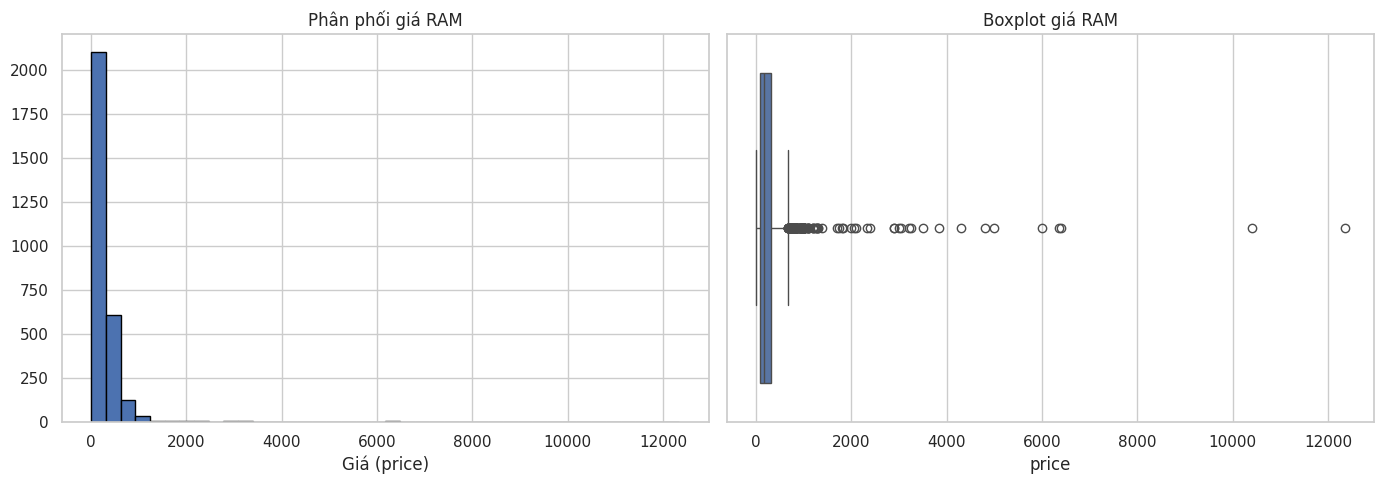

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(df_clean['price'], bins=40, edgecolor='black')
axes[0].set_title('Phân phối giá RAM')
axes[0].set_xlabel('Giá (price)')
sns.boxplot(x=df_clean['price'], ax=axes[1])
axes[1].set_title('Boxplot giá RAM')
plt.tight_layout()
plt.show()

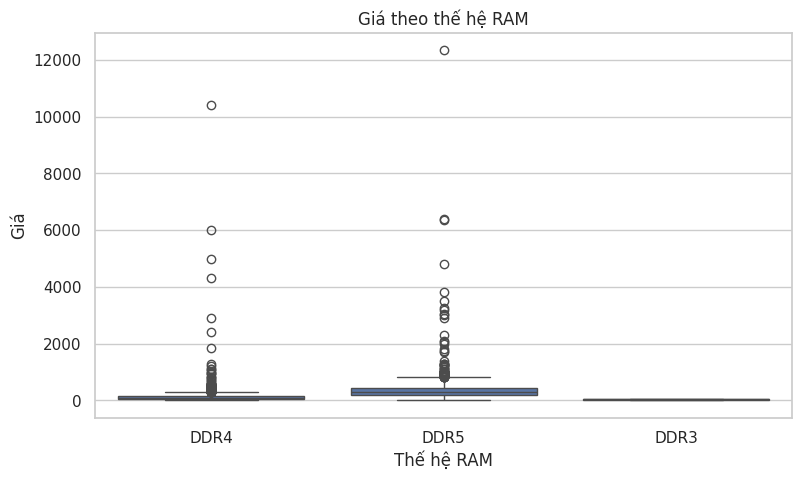

In [8]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=df_clean, x='ram_generation', y='price')
plt.title('Giá theo thế hệ RAM')
plt.xlabel('Thế hệ RAM'); plt.ylabel('Giá')
plt.show()

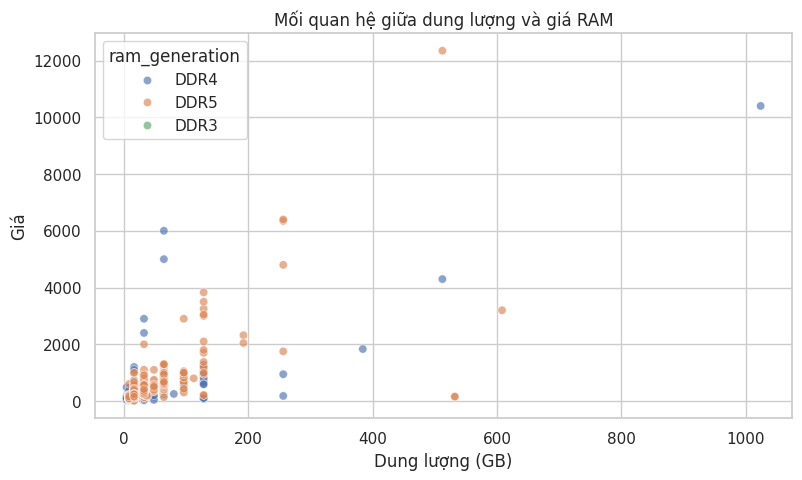

In [9]:
plt.figure(figsize=(9, 5))
sns.scatterplot(data=df_clean, x='capacity_gb', y='price',
                hue='ram_generation', alpha=0.65)
plt.title('Mối quan hệ giữa dung lượng và giá RAM')
plt.xlabel('Dung lượng (GB)'); plt.ylabel('Giá')
plt.show()

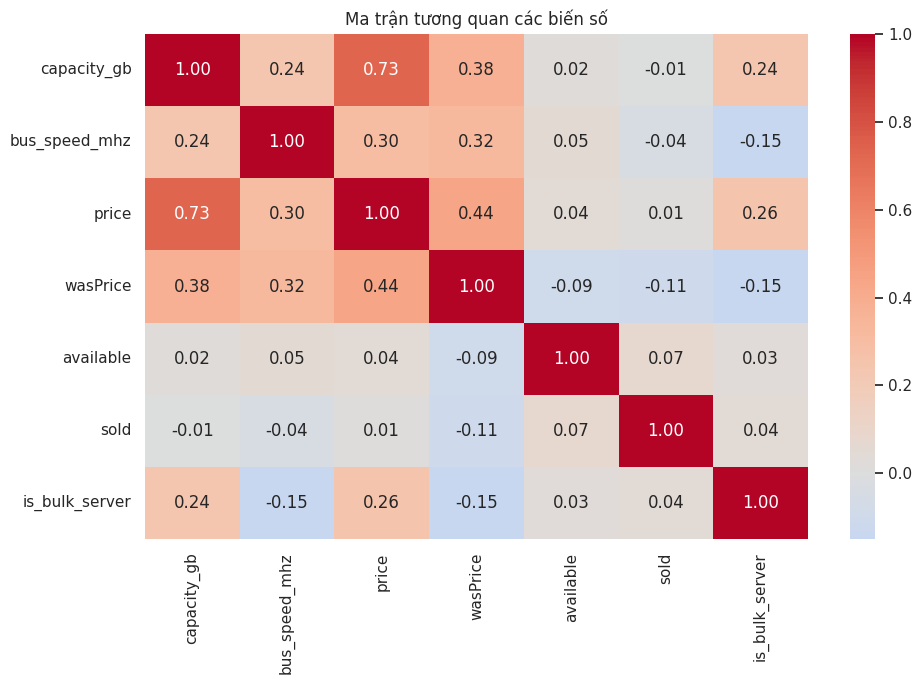

In [10]:
corr = df_clean.select_dtypes(include=np.number).corr()
plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Ma trận tương quan các biến số')
plt.tight_layout()
plt.show()

### Nhận xét EDA
- Giá RAM thường có phân phối lệch phải; cần xem xét biểu đồ và ngoại lai trước khi kết luận.
- Dung lượng, thế hệ RAM, bus speed, tình trạng sản phẩm và thông tin người bán có thể liên quan đến giá.
- Tương quan chỉ phản ánh quan hệ tuyến tính giữa biến số, không chứng minh quan hệ nhân quả.

## 5. Chuẩn bị dữ liệu cho mô hình

In [11]:
TARGET = 'price'

# Không dùng title, seller_id, mpn, itemLocation, lastUpdated để hạn chế
# đặc trưng định danh/văn bản tự do có quá nhiều giá trị riêng.
# wasPrice, available, sold được giữ làm đặc trưng nếu có trong dữ liệu.
drop_cols = ['price', 'title', 'seller_id', 'mpn', 'itemLocation', 'lastUpdated']
X = df_clean.drop(columns=[c for c in drop_cols if c in df_clean.columns])
y = df_clean[TARGET]

# Loại cột không có giá trị hoặc chỉ có duy nhất một giá trị
X = X.loc[:, X.nunique(dropna=False) > 1]

numeric_features = X.select_dtypes(include=['number', 'bool']).columns.tolist()
categorical_features = X.select_dtypes(exclude=['number', 'bool']).columns.tolist()

print('Biến số:', numeric_features)
print('Biến phân loại:', categorical_features)
print('Số đặc trưng đầu vào:', X.shape[1])

Biến số: ['capacity_gb', 'bus_speed_mhz', 'wasPrice', 'available', 'sold', 'is_bulk_server']
Biến phân loại: ['ram_generation', 'brand', 'condition', 'unit_type', 'type']
Số đặc trưng đầu vào: 11


In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

## 6. Huấn luyện mô hình XGBoost Regressor

In [13]:
model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', XGBRegressor(
        n_estimators=500,
        learning_rate=0.04,
        max_depth=5,
        min_child_weight=2,
        subsample=0.85,
        colsample_bytree=0.85,
        objective='reg:squarederror',
        eval_metric='rmse',
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

model.fit(X_train, np.log1p(y_train))
print('Huấn luyện hoàn tất.')

Huấn luyện hoàn tất.


## 7. Đánh giá mô hình

In [14]:
y_pred = np.expm1(model.predict(X_test))
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

metrics = pd.DataFrame({
    'Chỉ số': ['MAE', 'RMSE', 'R²'],
    'Giá trị': [mae, rmse, r2]
})
display(metrics)
print(f'MAE  : {mae:,.3f}')
print(f'RMSE : {rmse:,.3f}')
print(f'R²   : {r2:.4f}')

,Chỉ số,Giá trị
0,MAE,61.018161
1,RMSE,215.234545
2,R²,0.546740


MAE  : 61.018
RMSE : 215.235
R²   : 0.5467


,Giá thực tế,Giá dự đoán
0,95.99,71.075127
1,729.99,566.589111
2,299.95,318.488800
3,454.89,538.606995
4,299.99,329.901489
5,241.23,313.371094
6,139.49,166.496841
7,129.95,100.935966
8,96.95,94.687859
9,279.99,175.171890


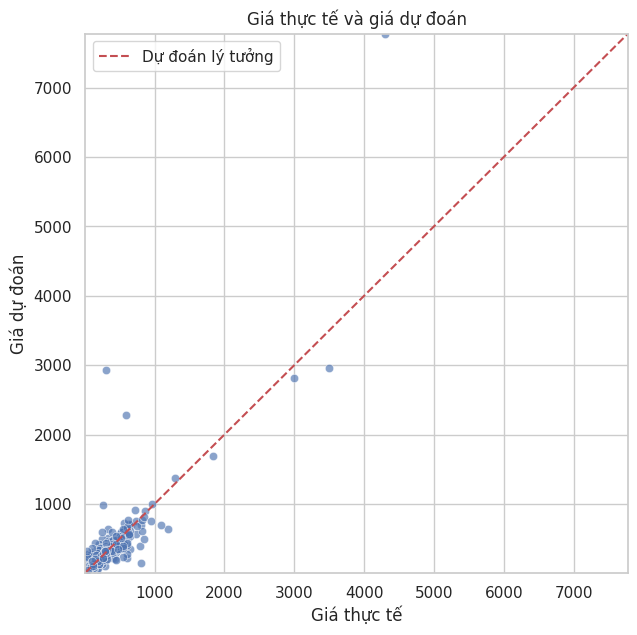

In [15]:
results = pd.DataFrame({'Giá thực tế': y_test.values, 'Giá dự đoán': y_pred})
display(results.head(15))

plt.figure(figsize=(7, 7))
sns.scatterplot(x=y_test, y=y_pred, alpha=0.65)
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
plt.plot(lims, lims, 'r--', label='Dự đoán lý tưởng')
plt.xlim(lims); plt.ylim(lims)
plt.xlabel('Giá thực tế'); plt.ylabel('Giá dự đoán')
plt.title('Giá thực tế và giá dự đoán')
plt.legend(); plt.show()

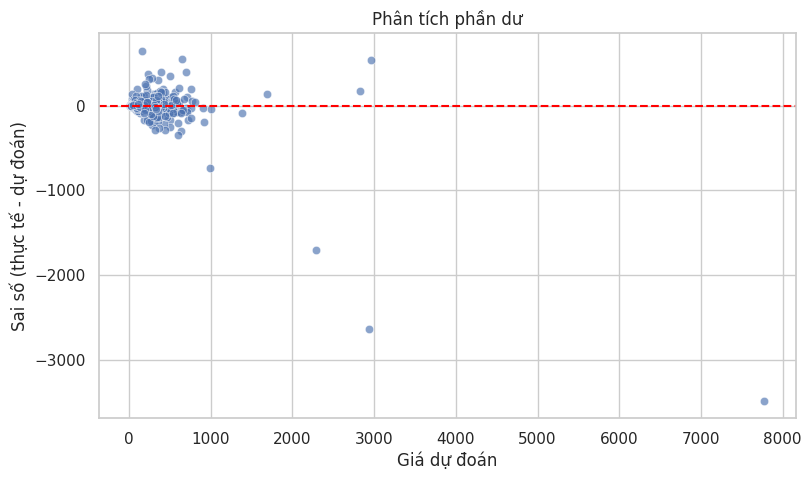

In [16]:
residuals = y_test - y_pred
plt.figure(figsize=(9, 5))
sns.scatterplot(x=y_pred, y=residuals, alpha=0.65)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Giá dự đoán'); plt.ylabel('Sai số (thực tế - dự đoán)')
plt.title('Phân tích phần dư')
plt.show()

## 8. Mức độ quan trọng của đặc trưng

,Đặc trưng,Mức độ quan trọng
8,cat__ram_generation_DDR5,0.340630
0,num__capacity_gb,0.134476
7,cat__ram_generation_DDR4,0.068844
61,cat__brand_Intel,0.028059
97,cat__brand_RigidRAM,0.023437
157,cat__type_288-Pin DDR5 SDRAM,0.022237
146,cat__condition_Used,0.021321
150,cat__unit_type_Single,0.021204
5,num__is_bulk_server,0.019957
265,cat__type_Server Memory,0.018413


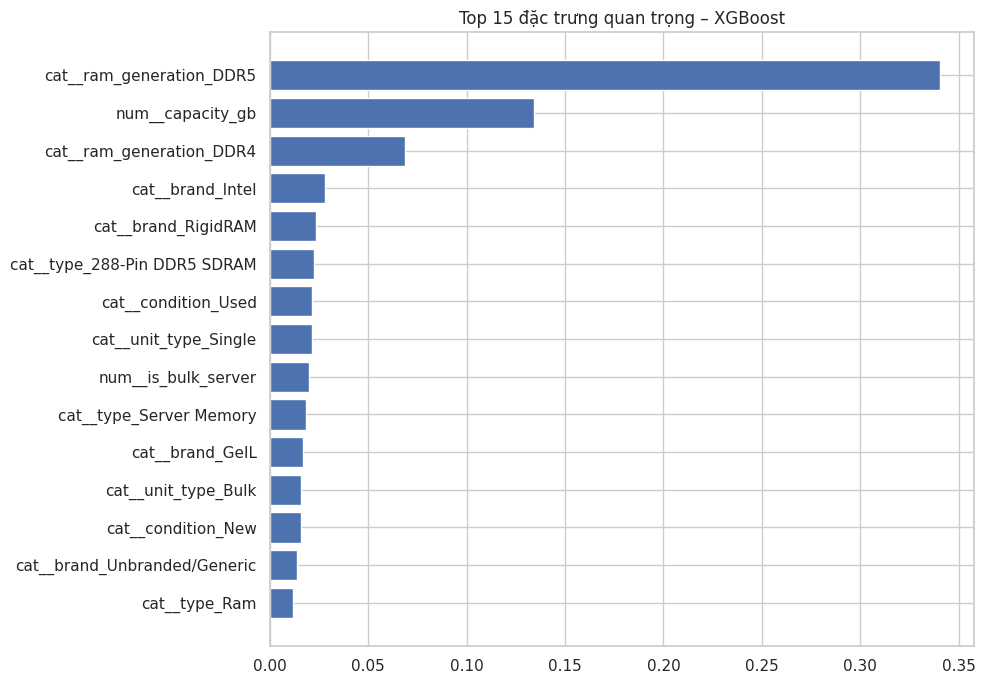

In [17]:
fitted_preprocessor = model.named_steps['preprocessor']
feature_names = fitted_preprocessor.get_feature_names_out()
importances = model.named_steps['regressor'].feature_importances_
importance_df = pd.DataFrame({
    'Đặc trưng': feature_names,
    'Mức độ quan trọng': importances
}).sort_values('Mức độ quan trọng', ascending=False)

display(importance_df.head(20))
plt.figure(figsize=(10, 7))
top_imp = importance_df.head(15).sort_values('Mức độ quan trọng')
plt.barh(top_imp['Đặc trưng'], top_imp['Mức độ quan trọng'])
plt.title('Top 15 đặc trưng quan trọng – XGBoost')
plt.tight_layout()
plt.show()

## 9. Thử dự đoán một sản phẩm

In [18]:
# Lấy một dòng từ tập kiểm tra để minh họa dự đoán
sample = X_test.iloc[[0]]
actual_price = y_test.iloc[0]
predicted_price = np.expm1(model.predict(sample)[0])

print('Giá thực tế :', round(float(actual_price), 2))
print('Giá dự đoán :', round(float(predicted_price), 2))
print('Sai số tuyệt đối:', round(abs(float(actual_price) - float(predicted_price)), 2))
display(sample)

Giá thực tế : 95.99
Giá dự đoán : 71.08
Sai số tuyệt đối: 24.91


,ram_generation,brand,condition,capacity_gb,bus_speed_mhz,unit_type,wasPrice,available,sold,type,is_bulk_server
141,DDR4,Kingston,Used,16.0,3200.0,Single,NaN,5.0,2.0,DDR4 SDRAM,0


## 10. Kết luận

Mô hình XGBoost Regressor đã được huấn luyện để dự đoán giá RAM dựa trên các thuộc tính sản phẩm và thông tin niêm yết. Ba chỉ số MAE, RMSE và R² được dùng để đánh giá chất lượng dự đoán trên tập kiểm tra.

**Khi trình bày kết quả:** ghi lại giá trị MAE, RMSE, R² thực tế sau khi chạy notebook; không tự đặt trước kết quả. Mô hình chỉ học từ dữ liệu đã cung cấp, nên khả năng dự đoán phụ thuộc vào chất lượng, phạm vi và thời điểm thu thập dữ liệu. Đây là mô hình tham khảo, không phải giá thị trường được đảm bảo.